# 📗 Notebook 9 — Case Study 3.2: Styrene / MMA Free-Radical Copolymerization
| | |
|---|---|
| ⏱ Time | ~25 min (simulations ≈ 20 s) |
| 🧭 Type | **steady state Monte Carlo** — Terminal model |
| 🎯 Goal | reproduce **Figures 3.9, 3.10, 3.14 and 3.16** with the book's parameters |
| 📖 Book | Sec. 3.2 · Tables 3.4–3.5 · Algorithm 3.3 · Stockmayer distribution (Eqs. 3.58–3.65) |

M1 = styrene, M2 = methyl methacrylate (MMA). Polymer radicals ending in M1 are **P**, those ending in M2 are **Q**. This notebook focuses on the code; the theory is in *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from numba import njit
plt.rcParams.update({"figure.figsize": (6, 3.8), "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz

## 1 · Kinetic parameters (Table 3.5)
Same Arrhenius form as Case Study 3.1 (cal/mol, min⁻¹, L/(mol·min)). Cross-termination and cross-transfer constants are built from the homo-constants, exactly as in the table.

In [2]:
R_gas, T = 1.987, 90 + 273.15
arrh = lambda A, E: A * np.exp(-E / (R_gas * T))

M_tot, I = 8.0, 0.016                       # mol/L
kd  = arrh(3.389e15, 31500); f = 0.7
ki1 = arrh(1e9, 7000);  ki2 = arrh(3e9, 7000)
kp11  = arrh(1.302e9, 7759);  ktM11 = arrh(5.14e9, 15230);  ktc11 = arrh(4.92e11, 3470)
kp22  = arrh(2.95e7, 4353);   ktM22 = arrh(2.41e9, 15541);  ktc22 = arrh(5.88e9, 701)
r1, r2 = 0.5224, 0.4839
kp12, kp21 = kp11 / r1, kp22 / r2
phi_tc = 25
ktc12 = ktc21 = np.sqrt(2 * ktc11 * ktc22) * phi_tc
ktM12 = ktM21 = np.sqrt(ktM11 * ktM22)

## 2 · The 18 probabilities (Sec. 3.2.1–3.2.4)
The function below follows the book's order:
1. **QSSA + LCA-II** for `[P]` and `[Q]` (Eqs. 3.53–3.57): `[Q] = ϕ[P]`, `[P] = √(f·k_d·[I] / k̂_tc)`
2. **Initiation** with M1 (Eq. 3.31)
3. **Propagation** of P and Q (Eqs. 3.34, 3.36) and which monomer adds (Eqs. 3.37, 3.40)
4. **Combination** vs transfer (Eqs. 3.43, 3.47) and which monomer receives the transfer (Eqs. 3.45, 3.49)

It also returns β and τ (Eqs. 3.62–3.63) for the Stockmayer solution, and the rates for Figure 3.10.

In [3]:
def probabilities(f1):
    M1, M2 = f1*M_tot, (1 - f1)*M_tot
    phi = kp12*M2 / (kp21*M1)                                    # Eq. 3.54
    khat = ktc11 + 2*ktc12*phi + ktc22*phi**2                    # Eq. 3.56
    P = np.sqrt(f*kd*I / khat); Q = phi*P                        # Eq. 3.57
    p = {}
    p["Pi1"]   = ki1*M1 / (ki1*M1 + ki2*M2)                                              # 3.31
    p["Pp1"]   = (kp11*M1 + kp12*M2) / (kp11*M1 + kp12*M2 + ktM11*M1 + ktM12*M2 + ktc11*P + ktc12*Q)  # 3.34
    p["Pp2"]   = (kp21*M1 + kp22*M2) / (kp21*M1 + kp22*M2 + ktM21*M1 + ktM22*M2 + ktc21*P + ktc22*Q)  # 3.36
    p["Pp11"]  = r1*M1 / (r1*M1 + M2)                                                    # 3.37
    p["Pp21"]  = M1 / (M1 + r2*M2)                                                       # 3.40
    p["Ptc1"]  = (ktc11*P + ktc12*Q) / (ktc11*P + ktc12*Q + ktM11*M1 + ktM12*M2)         # 3.43
    p["Ptc2"]  = (ktc21*P + ktc22*Q) / (ktc21*P + ktc22*Q + ktM21*M1 + ktM22*M2)         # 3.47
    p["PtM11"] = ktM11*M1 / (ktM11*M1 + ktM12*M2)                                        # 3.45
    p["PtM21"] = ktM21*M1 / (ktM21*M1 + ktM22*M2)                                        # 3.49
    Rp  = (kp11*M1 + kp12*M2)*P + (kp21*M1 + kp22*M2)*Q                                  # 3.24
    RtM = (ktM11*M1 + ktM12*M2)*P + (ktM21*M1 + ktM22*M2)*Q                              # 3.27
    Rtc = (ktc11*P + ktc12*Q)*P + (ktc21*P + ktc22*Q)*Q                                  # 3.30
    extra = dict(P=P, Q=Q, Rp=Rp, RtM=RtM, Rtc=Rtc, beta=Rtc/Rp, tau=RtM/Rp)             # 3.62, 3.63
    return p, extra

feeds = [0.1, 0.5, 0.9]
pd.DataFrame({f"f1 = {f1}": probabilities(f1)[0] for f1 in feeds}).style.format("{:.6f}")

,f1 = 0.1,f1 = 0.5,f1 = 0.9
Pi1,0.035714,0.250000,0.750000
Pp1,0.997886,0.998996,0.999269
Pp2,0.999552,0.999108,0.998254
Pp11,0.054860,0.343142,0.824611
Pp21,0.186738,0.673900,0.948977
Ptc1,0.980551,0.933349,0.849443
Ptc2,0.967140,0.984503,0.992388
PtM11,0.167561,0.644331,0.942211
PtM21,0.167561,0.644331,0.942211


### Figure 3.10: why the MWD depends on f1
These come straight from the rate equations — no simulation needed.

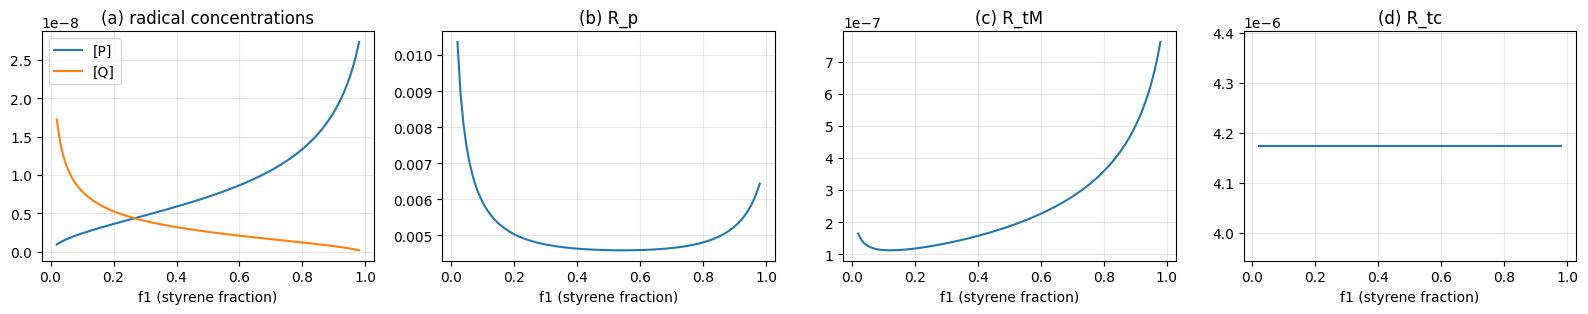

In [4]:
f_grid = np.linspace(0.02, 0.98, 100)
ex = [probabilities(x)[1] for x in f_grid]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
ax[0].plot(f_grid, [e["P"] for e in ex], label="[P]"); ax[0].plot(f_grid, [e["Q"] for e in ex], label="[Q]")
ax[0].set_title("(a) radical concentrations"); ax[0].legend()
for a, key, title in [(ax[1], "Rp", "(b) R_p"), (ax[2], "RtM", "(c) R_tM"), (ax[3], "Rtc", "(d) R_tc")]:
    a.plot(f_grid, [e[key] for e in ex]); a.set_title(title)
for a in ax: a.set_xlabel("f1 (styrene fraction)")
plt.tight_layout(); plt.show()

## 3 · Algorithm 3.3 in code
The variable `last` tracks the terminal unit (1 = P, 2 = Q). Instead of copying four probabilities every time `last` changes (lines 10, 13, 21, …), we store each probability in a small array indexed by `last`:
`Pp[last]`, `Padd1[last]` (= `P_p,11` or `P_p,21`), `Ptc[last]`, `PtM1[last]` (= `P_tM,11` or `P_tM,21`). Same logic, less code.

`D[k]` and `N1[k]` store the **length** and **number of M1 units** of the k-th dead chain (note the different convention from Case Study 3.1, footnote 13).

In [5]:
@njit
def grow(last, n, n1, Pp, Padd1):
    """Propagation loop (lines 4–14): add units until the radical stops."""
    while np.random.random() <= Pp[last]:          # Rnd ≤ P_p,last ?
        n += 1
        if np.random.random() <= Padd1[last]:      # Rnd ≤ P_p,last1 → add M1
            last = 1; n1 += 1
        else:                                      # add M2
            last = 2
    return last, n, n1

@njit
def start_unit(P1):
    """Pick the first unit of a new radical: M1 with probability P1."""
    return 1 if np.random.random() <= P1 else 2

**Main loop.** When a radical stops:
- **Combination** (`Rnd ≤ P_tc,last`): build a second radical. As in Case Study 3.1, if that partner terminates by **transfer**, it is stored as its own dead chain and a new partner is built — until one terminates by combination. Then store `n + m` and `n1 + m1`.
- **Transfer** (`Rnd > P_tc,last`): store the chain; the monomer that received the transfer (`P_tM,last1`) seeds the next radical.

New radicals that are not seeded by transfer start with M1 or M2 according to the initiation probability `P_i,1` (the *Chain Initiation* step of Figure 3.7).

In [6]:
@njit
def algorithm_3_3(N, Pi1, Pp, Padd1, Ptc, PtM1, seed=1):
    np.random.seed(seed)
    D = np.zeros(N, np.int64); N1 = np.zeros(N, np.int64); k = 0
    last = start_unit(Pi1); n = 1; n1 = 1 if last == 1 else 0
    while k < N:
        last, n, n1 = grow(last, n, n1, Pp, Padd1)
        if np.random.random() <= Ptc[last]:                    # combination
            l2 = start_unit(Pi1)
            while True:                                        # generate_second_chain()
                m = 1; m1 = 1 if l2 == 1 else 0
                l2, m, m1 = grow(l2, m, m1, Pp, Padd1)
                if np.random.random() <= Ptc[l2]:
                    break                                      # partner also combines
                D[k] = m; N1[k] = m1; k += 1                   # partner transferred → dead chain
                if k >= N: return D, N1
                l2 = start_unit(PtM1[l2])                      # transfer seeds the next partner
            D[k] = n + m; N1[k] = n1 + m1; k += 1              # D_{i+k, j+l}
            last = start_unit(Pi1)                             # new radical by initiation
        else:                                                  # transfer to monomer
            D[k] = n; N1[k] = n1; k += 1
            last = start_unit(PtM1[last])                      # M1 or M2 receives the radical
        n = 1; n1 = 1 if last == 1 else 0
    return D, N1

def run(f1, N=100_000, seed=1):
    p, ex = probabilities(f1)
    arr = lambda a, b: np.array([0.0, a, b])                   # index 0 unused, 1 = P, 2 = Q
    D, N1 = algorithm_3_3(N, p["Pi1"], arr(p["Pp1"], p["Pp2"]), arr(p["Pp11"], p["Pp21"]),
                          arr(p["Ptc1"], p["Ptc2"]), arr(p["PtM11"], p["PtM21"]), seed)
    return D, N1, ex

## 4 · Run the three feeds and validate
Checks: `Nn` and `Nw` against the Stockmayer/Flory solution (Eqs. 3.17–3.18 with copolymer β, τ), and the average composition `F̄1` against Mayo–Lewis (Eq. 3.60). The book used `N = 10⁶` for Figure 3.9; `N = 10⁵` is enough here (change `N` to compare).

In [7]:
N = 100_000
sims, rows = {}, {}
for f1 in feeds:
    D, N1, ex = run(f1, N)
    sims[f1] = (D, N1, ex)
    b, t = ex["beta"], ex["tau"]; f2 = 1 - f1
    F1_ML = (r1*f1**2 + f1*f2) / (r1*f1**2 + 2*f1*f2 + r2*f2**2)             # Eq. 3.60
    rows[f"f1 = {f1}"] = {"Nn (MC)": D.mean(), "Nn (Stockmayer)": 1/(t + b/2),
                          "Nw (MC)": (D**2).sum()/D.sum(), "Nw (Stockmayer)": (2*t + 3*b)/(b + t)**2,
                          "F̄1 (MC)": N1.sum()/D.sum(), "F̄1 (Mayo–Lewis)": F1_ML}
pd.DataFrame(rows).style.format("{:.4f}", subset=pd.IndexSlice[["F̄1 (MC)", "F̄1 (Mayo–Lewis)"], :]) \
                        .format("{:.0f}", subset=pd.IndexSlice[["Nn (MC)", "Nn (Stockmayer)", "Nw (MC)", "Nw (Stockmayer)"], :])

,f1 = 0.1,f1 = 0.5,f1 = 0.9
Nn (MC),2689,2018,2024
Nn (Stockmayer),2692,2019,2030
Nw (MC),4093,3109,3237
Nw (Stockmayer),4107,3114,3250
F̄1 (MC),0.1649,0.5062,0.8439
F̄1 (Mayo–Lewis),0.1650,0.5064,0.8440


## 5 · Figure 3.9: w-MWD in log scale
Log-spaced bins weighted by chain length.

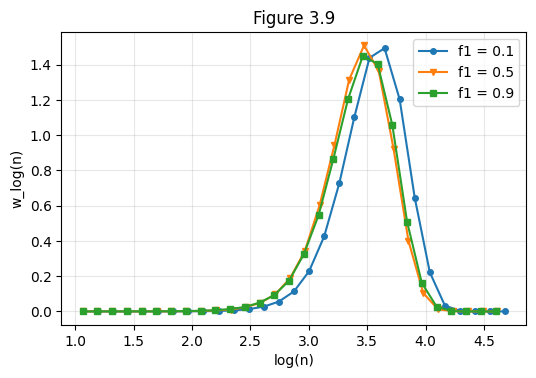

In [8]:
for f1, style in zip(feeds, ["o-", "v-", "s-"]):
    D = sims[f1][0]
    edges = np.logspace(1, np.log10(3*D.max()), 30)
    mass, _ = np.histogram(D, bins=edges, weights=D)
    x = np.log10(np.sqrt(edges[1:]*edges[:-1]))
    y = mass / np.diff(np.log10(edges)); y /= trapz(y, x)
    plt.plot(x, y, style, ms=4, label=f"f1 = {f1}")
plt.xlabel("log(n)"); plt.ylabel("w_log(n)"); plt.legend(); plt.title("Figure 3.9"); plt.show()

## 6 · Figure 3.14: CCD vs. the Stockmayer distribution
**Monte Carlo CCD** (Algorithm 3.4): `F1 = N1/D` per chain, then a histogram over `F1` weighted by chain length.

**Stockmayer CCD** (Eq. 3.64), with `y = F1 − F̄1` and the composition variance parameter (Eq. 3.61) `ϕ = F̄1(1 − F̄1)·√(1 − 4F̄1(1 − F̄1)(1 − r1r2))`:

`w_y = 3ϕ²(β+τ)[2(β+τ)(τ + 5β/4)ϕ + y²τ] / [2(β+τ)ϕ + y²]^(7/2)`

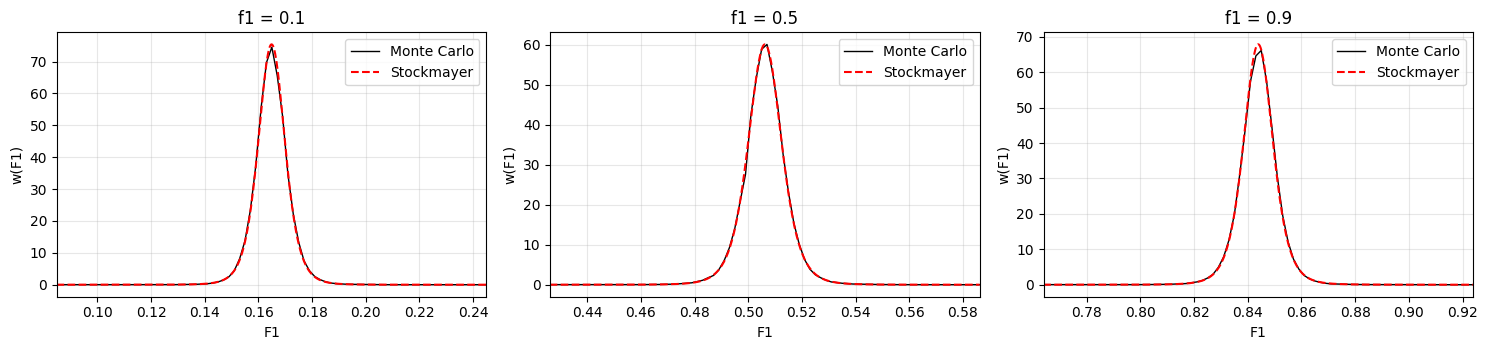

In [9]:
def stockmayer_ccd(y, F1bar, beta, tau):
    phi = F1bar*(1 - F1bar)*np.sqrt(1 - 4*F1bar*(1 - F1bar)*(1 - r1*r2))          # Eq. 3.61
    s = beta + tau
    return 3*phi**2*s*(2*s*(tau + 1.25*beta)*phi + y**2*tau) / (2*s*phi + y**2)**3.5     # Eq. 3.64

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, f1 in zip(ax, feeds):
    D, N1, ex = sims[f1]
    F1 = N1 / D
    dF = 0.002
    edges = np.arange(0, 1 + dF, dF)
    Y, _ = np.histogram(F1, bins=edges, weights=D)
    ccd = Y / Y.sum() / dF
    F1bar = N1.sum() / D.sum()
    Fg = np.linspace(0, 1, 4001)
    a.plot(0.5*(edges[1:] + edges[:-1]), ccd, "k-", lw=1, label="Monte Carlo")
    a.plot(Fg, stockmayer_ccd(Fg - F1bar, F1bar, ex["beta"], ex["tau"]), "r--", label="Stockmayer")
    a.set_xlim(F1bar - 0.08, F1bar + 0.08); a.set_xlabel("F1"); a.set_ylabel("w(F1)")
    a.set_title(f"f1 = {f1}"); a.legend()
plt.tight_layout(); plt.show()

## 7 · Figure 3.16: bivariate CLD × CCD
Monte Carlo (Algorithm 3.5: 2D histogram weighted by chain length) next to the Stockmayer bivariate distribution (Eq. 3.58), both on a log(n) axis (`× 2.3026·n`, Eq. 3.69). Shown for `f1 = 0.5`.

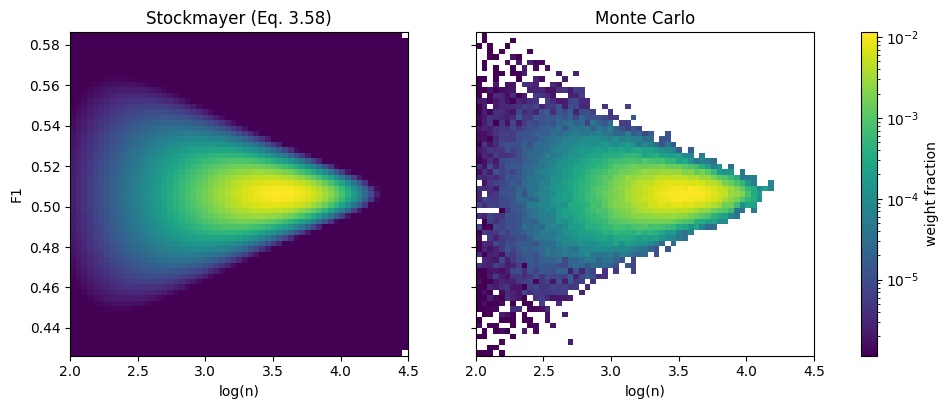

In [10]:
f1 = 0.5
D, N1, ex = sims[f1]; F1 = N1 / D; F1bar = N1.sum() / D.sum()
b, t = ex["beta"], ex["tau"]; s = b + t
phi = F1bar*(1 - F1bar)*np.sqrt(1 - 4*F1bar*(1 - F1bar)*(1 - r1*r2))

logn_edges = np.linspace(2, 4.5, 60)       # n ≥ 100: very short chains have only a few possible F1 values
F_edges = np.linspace(F1bar - 0.08, F1bar + 0.08, 60)
M_mc, _, _ = np.histogram2d(np.log10(D), F1, bins=[logn_edges, F_edges], weights=D)
M_mc /= M_mc.sum()

lg = 0.5*(logn_edges[1:] + logn_edges[:-1]); Fc = 0.5*(F_edges[1:] + F_edges[:-1])
nn, FF = np.meshgrid(10**lg, Fc, indexing="ij"); y = FF - F1bar
w_ny = nn*s*(t + 0.5*b*s*nn)*np.exp(-s*nn) * np.sqrt(nn/(2*np.pi*phi)) * np.exp(-nn*y**2/(2*phi))   # Eq. 3.58
M_st = 2.3026*nn*w_ny; M_st /= M_st.sum()                                                            # Eq. 3.69

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
vmax = max(M_mc.max(), M_st.max())
for a, Mx, title in [(ax[0], M_st, "Stockmayer (Eq. 3.58)"), (ax[1], M_mc, "Monte Carlo")]:
    pc = a.pcolormesh(logn_edges, F_edges, Mx.T, cmap="viridis", norm=LogNorm(vmin=vmax*1e-4, vmax=vmax))
    a.set_xlabel("log(n)"); a.set_title(title); a.grid(False)
ax[0].set_ylabel("F1"); fig.colorbar(pc, ax=ax, label="weight fraction"); plt.show()

## ✅ What the code taught us
- 18 probabilities, but only one idea: a **hierarchy** of `Rnd ≤ P` decisions (propagate? → which monomer? / combine? → which monomer receives the transfer?).
- Indexing probabilities by the terminal unit (`Pp[last]`) keeps the Terminal model compact.
- Three independent checks — Stockmayer averages, Mayo–Lewis, Stockmayer CCD — all agree with the simulation.

### 🧪 Try it yourself
1. Run `f1 = 0.3` and `0.7`. Where is the minimum in Nn?
2. Set `r1 = r2 = 1` (Bernoullian). How does the CCD width change?
3. Make the CCD bins 10× finer (`dF = 0.0002`). When does the Monte Carlo CCD become too noisy, and how many chains fix it?

➡️ **Next: Notebook 10 — Dynamic Monte Carlo case study: choosing the control volume**